# Benchmark error analysis

In [ ]:
import gzip
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from final_training import SPFeatures   # needed to load the SVM model

In [2]:
df = pd.read_csv("benchmarking_predictions.tsv", sep = "\t")
AMINO_ACIDS = list("ARNDCQEGHILKMFPSTWYV")
POSITIONS = [-13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 1, 2]
MODELS = {"von Heijne": "pred_von_heijne", "SVM": "pred_svm"}

TRAIN_FILE = "../0.4_Von_Heijne/training_5folds.tsv"
EXPECTED_FILE = "../0.4_Von_Heijne/training_positive_contexts.tsv"
MODEL_FILE = "../0.5_feature_selection_svm/D24_svm_final_model.pkl.gz"
df.head()

,accession,label,organism,kingdom,length,cleavage_site,tm_in_first_90,sequence,vh_score,pred_von_heijne,pred_svm
0,Q8MMH3,1,Pimpla hypochondriaca (Parasitoid wasp),Metazoa,488,19.0,NaN,MWSPLILPLLAQIFACAFGDAVNEGCNVDPKGIHGLWYLDEPFGVY...,6.214328,0,1
1,Q6TPK4,1,Actinidia deliciosa (Kiwi),Plants,116,26.0,NaN,MVPKPLSLLLFLLLALSAAVVGGRKLVAAGGWRPIESLNSAEVQDV...,10.603172,1,1
2,Q62632,1,Rattus norvegicus (Rat),Metazoa,306,18.0,NaN,MWKRWLALALVTIALVHGEEEQRSKSKICANVFCGAGRECAVTEKG...,9.458926,1,1
3,P47710,1,Homo sapiens (Human),Metazoa,185,15.0,NaN,MRLLILTCLVAVALARPKLPLRYPERLQNPSESSEPIPLESREEYM...,12.218489,1,1
4,Q8TAL6,1,Homo sapiens (Human),Metazoa,211,18.0,NaN,MVFLKFFCMSFFCHLCQGYFDGPLYPEMSNGTLHHYFVPDGDYEEN...,8.166644,1,0


In [3]:
print("1. ERROR DISTRIBUTION AMONG TAXA (KINGDOMS)")

for name, col in MODELS.items():
    print(f"\n--- Error distribution among taxa: {name} ---")
    summary = df.groupby("kingdom").apply(lambda g: pd.Series({
        "Total": len(g),
        "Positives (SP)": (g["label"] == 1).sum(),
        "Negatives (non-SP)": (g["label"] == 0).sum(),
        "FP": ((g["label"] == 0) & (g[col] == 1)).sum(),
        "FN": ((g["label"] == 1) & (g[col] == 0)).sum(),
    }), include_groups=False).astype(int)

    summary["FPR (%)"] = (summary["FP"] / summary["Negatives (non-SP)"] * 100).round(2)
    summary["FNR (%)"] = (summary["FN"] / summary["Positives (SP)"] * 100).round(2)
    print(summary.to_string())

1. ERROR DISTRIBUTION AMONG TAXA (KINGDOMS)

--- Error distribution among taxa: von Heijne ---
         Total  Positives (SP)  Negatives (non-SP)  FP  FN  FPR (%)  FNR (%)
kingdom                                                                     
Fungi      544              22                 522   5   7     0.96    31.82
Metazoa   1118             179                 939  48  45     5.11    25.14
Other       44               1                  43   4   0     9.30     0.00
Plants     330              18                 312  18   3     5.77    16.67

--- Error distribution among taxa: SVM ---
         Total  Positives (SP)  Negatives (non-SP)  FP  FN  FPR (%)  FNR (%)
kingdom                                                                     
Fungi      544              22                 522   3   8     0.57    36.36
Metazoa   1118             179                 939  30  21     3.19    11.73
Other       44               1                  43   1   1     2.33   100.00
Plants     330

In [4]:
print("2. FALSE POSITIVE ANALYSIS: TRANSMEMBRANE (TM) HELICES")

print("\n--- FP with TM helix within first 90 residues ---")
for name, col in MODELS.items():
    fp_mask = (df["label"] == 0) & (df[col] == 1)
    tot_fp = fp_mask.sum()
    tm_fp = (fp_mask & (df["tm_in_first_90"] == True)).sum()
    perc = (tm_fp / tot_fp * 100) if tot_fp > 0 else 0.0
    print(f"{name:10s} -> Total FP: {tot_fp:3d} | with TM: {tm_fp:3d} ({perc:.2f}%)")

2. FALSE POSITIVE ANALYSIS: TRANSMEMBRANE (TM) HELICES

--- FP with TM helix within first 90 residues ---
von Heijne -> Total FP:  75 | with TM:  41 (54.67%)
SVM        -> Total FP:  38 | with TM:  23 (60.53%)


In [ ]:
print("3. FALSE NEGATIVE ANALYSIS (VON HEIJNE)")

def extract_context(row):
    if pd.isna(row["cleavage_site"]):
        return None
    c = int(row["cleavage_site"])
    seq = str(row["sequence"])
    start, end = c - 13, c + 2
    if start >= 0 and end <= len(seq):
        ctx = seq[start:end]
        return ctx if len(ctx) == len(POSITIONS) else None
    return None

df["cleavage_context"] = df.apply(extract_context, axis=1)

tp_vh = df[(df["label"] == 1) & (df["pred_von_heijne"] == 1)].dropna(subset = ["cleavage_context"])
fn_vh = df[(df["label"] == 1) & (df["pred_von_heijne"] == 0)].dropna(subset = ["cleavage_context"])

# amino acid frequency matrix (%) of the 15 positions of the cleavage context, for TP and FN
def get_position_frequencies(series_contexts):
    matrix = pd.DataFrame(0.0, index = POSITIONS, columns = AMINO_ACIDS)
    for pos_idx, pos_val in enumerate(POSITIONS):
        counts = series_contexts.str[pos_idx].value_counts(normalize = True) * 100
        for aa, val in counts.items():
            if aa in matrix.columns:
                matrix.at[pos_val, aa] = val
    return matrix.round(2)

tp_freq_matrix = get_position_frequencies(tp_vh["cleavage_context"])
fn_freq_matrix = get_position_frequencies(fn_vh["cleavage_context"])
diff_freq_matrix = (fn_freq_matrix - tp_freq_matrix).round(2)

print("\n--- Differential aa frequency (FN - TP) in the cleavage site (15 positions x 20 AA) ---")
print(diff_freq_matrix.to_string())
print("\n--- Negative values ---> amino acid more frequent in TP than in FN")
print("\n--- Positive values ---> amino acid more frequent in FN than in TP")

3. FALSE NEGATIVE ANALYSIS (VON HEIJNE)

--- Differential aa frequency (FN - TP) in the cleavage site (15 positions x 20 AA) ---
         A     R     N     D      C     Q     E     G     H      I      L     K     M      F     P     S     T     W     Y      V
-13   1.82 -0.61  0.00 -0.61  -4.85 -0.61  0.00  0.61  0.00   3.03 -34.54 -0.61  5.45   1.21  2.43  6.06  2.43  4.85  3.03  10.91
-12  -3.64  0.00  0.00 -0.61  -0.60  1.82  0.00  3.63  1.82   9.69 -16.97  0.00  4.24  -6.06  1.82  1.81  3.03 -0.61  1.82  -1.21
-11  -1.21  0.00  0.00  0.00  -3.03  1.21 -0.61  0.00  1.82  -4.25 -20.00  0.00  4.85   2.42  1.21  9.09  3.63 -0.61  3.03   2.43
-10  -1.21 -0.61  1.82  0.00   2.42  0.00  0.00 -4.85 -0.61   5.45  -9.09  0.00 -1.21  10.30  1.22 -4.84  0.61 -0.60  0.00   1.21
-9   -9.09  1.82  1.82 -0.61  -3.03  1.21  1.21 -4.24 -0.61  11.52 -13.34  0.00  5.45   6.06  3.63 -4.84  3.03 -1.21 -0.61   1.82
-8   -8.48  0.00  1.21 -0.61 -10.30  6.66  0.00  0.00  1.82  10.31 -12.73  0.00  6.67   8.4

In [ ]:
print("\n--- Input files for the sequence logos (WebLogo website) ---")

# von Heijne FN: cleavage-site contexts in FASTA format
with open("fn_vh_contexts.fasta", "w") as f:
    for _, r in fn_vh.iterrows():
        f.write(f">{r['accession']}|site_{int(r['cleavage_site'])}\n{r['cleavage_context']}\n")

# expected logo: cleavage-site contexts of the training positives (the one with unknown residues is removed)
expected = pd.read_csv(EXPECTED_FILE, sep = "\t")["cleavage_context"]
expected = expected[~expected.str.contains("X")]

with open("logo_expected_training_positives.fasta", "w") as f:
    for i, ctx in enumerate(expected):
        f.write(f">{i}\n{ctx}\n")

print(len(fn_vh), "FN contexts,", len(expected), "expected contexts")      # 55 and 881


--- Input files for the sequence logos (WebLogo website) ---
55 FN contexts, 881 expected contexts


In [ ]:
print("4. DIAGNOSING SVM FALSE NEGATIVES: TRAINING POSITIVES vs BENCHMARK TP vs BENCHMARK FN")

with gzip.open(MODEL_FILE, "rb") as fh:
    svm = pickle.load(fh)
feat = svm.named_steps["features"]   # n was learned on the training set, not on the benchmark

train = pd.read_csv(TRAIN_FILE, sep = "\t")
groups = {
    "training positives": train[train["label"] == 1],
    "benchmark TP": df[(df["label"] == 1) & (df["pred_svm"] == 1)],
    "benchmark FN": df[(df["label"] == 1) & (df["pred_svm"] == 0)],
}

# 24 features + SP length of every protein, with the group it belongs to
X = pd.concat([pd.DataFrame(feat.transform(g), columns = feat.get_feature_names_out())
               .assign(SP_length = g["cleavage_site"].to_numpy(), group = name)
               for name, g in groups.items()], ignore_index = True)
mean_X = X.groupby("group").mean().T[list(groups)]

SVM_FEATURES = ["SP_length", "KD_max", "KD_mean", "KD_max_position", "nregion_charge"]
print("\n--- Mean value of the SP length and of the other features ---")
print(mean_X.loc[SVM_FEATURES].round(3).to_string())

print("\n--- SP length statistics ---")
print(X.groupby("group")["SP_length"].describe().loc[list(groups)].round(2).to_string())

print(f"\n--- AA composition (%) within the first n = {feat.n_} residues ---")
print((100 * mean_X.drop(SVM_FEATURES)).round(1).rename(index = lambda c: c.replace("AAC_", "")).to_string())

4. DIAGNOSING SVM FALSE NEGATIVES: TRAINING POSITIVES vs BENCHMARK TP vs BENCHMARK FN



--- Mean value of the SP length and of the other features ---
group            training positives  benchmark TP  benchmark FN
SP_length                    23.053        22.101        25.516
KD_max                        3.426         3.491         2.933
KD_mean                       0.520         0.599         0.401
KD_max_position              13.049        11.370        13.452
nregion_charge                0.520         0.614         0.194

--- SP length statistics ---
                    count   mean   std   min   25%   50%   75%   max
group                                                               
training positives  882.0  23.05  6.14  14.0  19.0  22.0  25.0  83.0
benchmark TP        189.0  22.10  4.24  15.0  19.0  22.0  25.0  33.0
benchmark FN         31.0  25.52  9.62  17.0  19.0  24.0  28.5  64.0

--- AA composition (%) within the first n = 22 residues ---
group  training positives  benchmark TP  benchmark FN
A                    13.4          13.7           9.4
R        

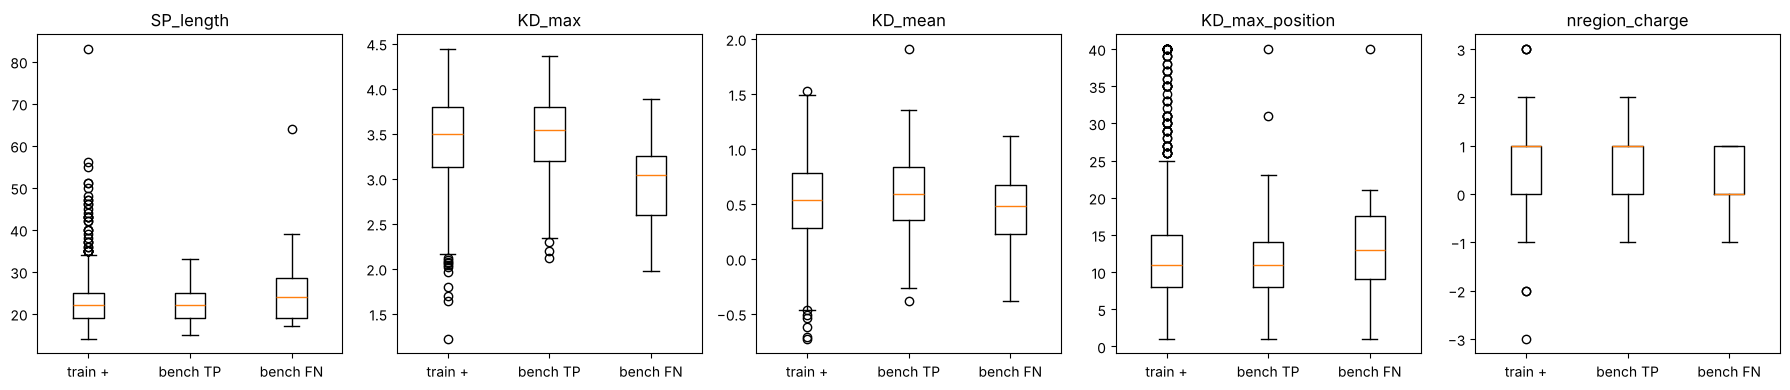

In [8]:
# distribution of the SP length and of the other features in the three groups
fig, axes = plt.subplots(1, len(SVM_FEATURES), figsize = (18, 4))
for ax, feature in zip(axes, SVM_FEATURES):
    ax.boxplot([X.loc[X["group"] == name, feature] for name in groups])
    ax.set_xticks([1, 2, 3], ["train +", "bench TP", "bench FN"])
    ax.set_title(feature)

fig.tight_layout()
fig.savefig("benchmark_svm_fn_features.png", dpi = 200)
plt.show()